In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import time
import jax.numpy as jnp
import equinox as eqx
import optax
import matplotlib.pyplot as plt

from pathlib import Path
from jax import random, vmap
from jax.lax import scan, dot_general, dynamic_slice_in_dim
from jax.tree_util import tree_map, tree_flatten
from jax.nn import gelu

%config InlineBackend.figure_format='retina'

# Fourier Neural Operator

In the previous tutorials a network was trained for a **single** problem: a new coefficient $a(x)$ required a new training. *Operator learning* aims at a different goal: to learn the whole solution operator
$$
\mathcal{G}: v \longrightarrow u,
$$
which maps the input functions of a PDE (coefficients, right-hand side, initial condition) to its solution, from a dataset of pairs $(v_i, u_i)$. After the training the solution for a new input is a single forward pass of the network.

### Fourier layer

The *Fourier Neural Operator* (FNO) represents $\mathcal{G}$ as a composition of an encoder, several Fourier layers, and a decoder. The input functions, sampled on a grid together with the grid coordinates, are first lifted pointwise to $n$ channels, $v_0(x)=P\,[x, v(x)]$. Each Fourier layer then updates the channels as
$$
v_{k+1}(x) = v_k(x) + \sigma\Big(W_k\,v_k(x) + \mathcal{F}^{-1}\big[R_k\cdot\mathcal{F}[v_k]\big](x)\Big),
$$
where $\mathcal{F}$ is the Fourier transform, $W_k$ is a pointwise (a $1\times1$ convolution) linear map, and $R_k$ is a learnable complex matrix **for every retained Fourier mode**: only the lowest `N_modes` modes are kept, the others are discarded. The multiplication by $R_k$ in the Fourier space is a global convolution with a learnable kernel, so a single layer already has a global receptive field, and the cost of a layer is $O(N\log N)$ thanks to the FFT. Finally, the decoder $Q$ maps the channels to the solution, $u(x)=Q\,v_K(x)$. Because all the operations are defined for functions, and the weights do not depend on the grid, the trained network can in principle be evaluated on a different resolution.

### Implementation in this notebook

We use the *factorised* variant of the FNO, in which the spectral convolution acts separately along every coordinate axis (the results are summed), so the number of parameters grows linearly and not exponentially with the dimension of the domain (here the domain is one-dimensional, so the difference is immaterial). Each layer is
$$
v_{k+1} = v_k + W_2\,\sigma\big(W_1\,\mathcal{S}_k(v_k)\big),
$$
with $\mathcal{S}_k(v)=\sum_d\mathcal{F}_d^{-1}\big[R_{k,d}\cdot\mathcal{F}_d[v]\big]$ and a pointwise two-layer feed-forward network instead of the linear $W_k$. Some practical points:

- the weights $R_k$ are complex, so JAX returns the conjugated gradient, and we apply `conj` to the gradients before passing them to the optimiser;
- the encoder and decoder weights and the spectral weights are initialised with small scales `s1`, `s3`, so that at the beginning of the training the network is close to the identity;
- the loss is the squared $\ell_2$ distance between the predicted and the true solution (summed over the grid), averaged over a minibatch;
- we train with the Lion optimiser at a constant learning rate, and we do not tune the training: the aim is to show what the FNO does.

*References:* Z. Li, N. Kovachki, K. Azizzadenesheli, B. Liu, K. Bhattacharya, A. Stuart, A. Anandkumar, [Fourier Neural Operator for Parametric Partial Differential Equations](https://arxiv.org/abs/2010.08895), ICLR 2021; for the factorised variant: A. Tran, A. Mathews, L. Xie, C. S. Ong, [Factorized Fourier Neural Operators](https://arxiv.org/abs/2111.13802), ICLR 2023; for the optimiser: X. Chen et al., [Symbolic Discovery of Optimization Algorithms](https://arxiv.org/abs/2302.06675), NeurIPS 2023.

In [2]:
def normalize_conv(A, s1=1.0, s2=1.0):
    # rescale the weights and the bias of a convolution (used to choose the initial scale)
    A = eqx.tree_at(lambda x: x.weight, A, A.weight * s1)
    try:
        A = eqx.tree_at(lambda x: x.bias, A, A.bias * s2)
    except:
        pass
    return A

class FFNO(eqx.Module):
    encoder: eqx.Module
    decoder: eqx.Module
    convs1: list
    convs2: list
    A: jnp.array

    def __init__(self, N_layers, N_features, N_modes, D, key, s1=1.0, s2=1.0, s3=1.0):
        n_in, n_processor, n_out = N_features

        keys = random.split(key, 3 + 2*N_layers)
        self.encoder = normalize_conv(eqx.nn.Conv(D, n_in, n_processor, 1, key=keys[-1]), s1=s1, s2=s2)
        self.decoder = normalize_conv(eqx.nn.Conv(D, n_processor, n_out, 1, key=keys[-2]), s1=s1, s2=s2)
        self.convs1 = [normalize_conv(eqx.nn.Conv(D, n_processor, n_processor, 1, key=key), s1=s1, s2=s2) for key in keys[:N_layers]]
        self.convs2 = [normalize_conv(eqx.nn.Conv(D, n_processor, n_processor, 1, key=key), s1=s1, s2=s2) for key in keys[N_layers:2*N_layers]]
        # complex spectral weights: [layer, c_in, c_out, mode, axis]
        self.A = random.normal(keys[-3], [N_layers, n_processor, n_processor, N_modes, D], dtype=jnp.complex64) * s3

    def __call__(self, u, x):
        u = jnp.concatenate([x, u], 0)  # the coordinates are the additional input channels
        u = self.encoder(u)
        for conv1, conv2, A in zip(self.convs1, self.convs2, self.A):
            u += gelu(conv2(gelu(conv1(self.spectral_conv(u, A)))))
        u = self.decoder(u)
        return u

    def spectral_conv(self, v, A):
        # for each axis: FFT, keep the lowest modes, multiply by A (matrix product over channels in every mode), inverse FFT
        u = 0
        N = v.shape
        for i in range(A.shape[-1]):
            u_ = dynamic_slice_in_dim(jnp.fft.rfft(v, axis=i+1), 0, A.shape[-2], axis=i+1)
            u_ = dot_general(A[:, :, :, i], u_, (((1,), (0,)), ((2, ), (i+1, ))))
            u_ = jnp.moveaxis(u_, 0, i+1)
            u += jnp.fft.irfft(u_, axis=i+1, n=N[i+1])
        return u

### Loss and optimisation step

The loss for a single sample is $\|u_\theta(v)-u\|_2^2$, and for a minibatch it is the average over its samples. As in the PINN tutorials, the training loop is compiled with `scan`, and the indices of the minibatches are pregenerated in advance.

In [3]:
def l2_loss(model, input, target, x):
    X = model(input, x)
    error = jnp.mean(jnp.sum(((X - target).reshape(target.shape[0], -1,))**2, axis=1))
    return error

def batch_l2_loss(model, input, target, x):
    res = vmap(l2_loss, in_axes=(None, 0, 0, None))(model, input, target, x)
    return jnp.mean(res)

l2_compute_loss_and_grads = eqx.filter_value_and_grad(batch_l2_loss)

def l2_make_step_scan(carry, n, optim):
    model, features, targets, x, opt_state = carry
    loss, grads = l2_compute_loss_and_grads(model, features[n], targets[n], x)
    grads = tree_map(lambda x: x.conj(), grads)  # the spectral weights are complex
    updates, opt_state = optim.update(grads, opt_state, eqx.filter(model, eqx.is_array))
    model = eqx.apply_updates(model, updates)
    return [model, features, targets, x, opt_state], loss

def make_prediction_scan(carry, i):
    model, features, coords = carry
    prediction = model(features[i], coords)
    return carry, prediction

# Datasets

We use the datasets generated in the previous tutorials, 1000 samples each on a grid of 512 points. The first 900 samples are used for training, and the last 100 are the test set, which is never seen by the network during the training.

| name | input $v$ | output $u$ |
|---|---|---|
| Burgers | initial condition $u_0(x)$ | solution of the Burgers equation at the final time |
| Diffusion | coefficient $a(x)$ and right-hand side $f(x)$ (two channels) | solution of $-\frac{d}{dx}\left(a(x) \frac{du(x)}{dx}\right)=f(x)$ |
| Diffusion, constant source | coefficient $a(x)$ (one channel) | solution of $-\frac{d}{dx}\left(a(x) \frac{du(x)}{dx}\right)=f(x)$ with a constant $f(x)$ |

The inputs and the outputs are divided by their maximal absolute values. The grid coordinates are passed to the network as an additional input channel.

In [4]:
# the repository root is the closest parent of the working directory that contains `notebooks`
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "notebooks").is_dir())
data_dir = root / "data"

In [5]:
def load_dataset(dataset_name):
    # returns arrays of shape (samples, channels, grid points), coordinates of shape (1, grid points)
    if dataset_name == 'Burgers':
        data = jnp.load(data_dir / "burgers_dataset.npz")
        features = jnp.expand_dims(data["initial condition"], 1)
    elif dataset_name == 'Diffusion':
        data = jnp.load(data_dir / "diffusion_dataset.npz")
        features = jnp.stack([data["diffusion coefficient"], data["righ-hand side"]], axis=1)
    elif dataset_name == 'Diffusion_constant_source':
        data = jnp.load(data_dir / "diffusion_dataset_2.npz")
        features = jnp.expand_dims(data["diffusion coefficient"], axis=1)
    targets = jnp.expand_dims(data["solution"], 1)
    coordinates = jnp.expand_dims(data["grid points"], 0)

    features = features / jnp.max(jnp.abs(features))
    targets = targets / jnp.max(jnp.abs(targets))
    return features, targets, coordinates

# Training

All three problems are trained with the same network and the same hyperparameters. The function `train` loads a dataset, trains the FNO, and returns the model together with the training history and the relative errors $\|u_\theta-u\|_2/\|u\|_2$ of all samples . For the training and the test sets we report the mean, the median, the minimal and the maximal error. The median is less sensitive than the mean to a few samples with a large error, and the minimum and the maximum show the range of the quality.

In [6]:
N_processor = 64  # number of channels in the Fourier layers
N_layers = 4
N_modes = 16  # number of retained Fourier modes
N_epoch = 400
N_train = 900
N_batch = 10
learning_rate = 1e-4
N_run = N_epoch * N_train // N_batch  # total number of updates

In [7]:
def train(dataset_name, key=random.PRNGKey(45)):
    features, targets, coordinates = load_dataset(dataset_name)
    D = features.ndim - 2  # dimension of the domain
    keys = random.split(key)

    N_features = [coordinates.shape[0] + features.shape[1], N_processor, targets.shape[1]]
    model = FFNO(N_layers, N_features, N_modes, D, keys[0], s1=1e-1, s2=0, s3=1e-1)
    # complex weights count twice
    model_size = sum(tree_map(lambda x: jnp.size(x) if x.dtype == jnp.float32 else 2*jnp.size(x), tree_flatten(model)[0], is_leaf=eqx.is_array))
    optim = optax.lion(learning_rate=learning_rate)
    opt_state = optim.init(eqx.filter(model, eqx.is_array))
    n = random.choice(keys[1], N_train, shape=(N_run, N_batch))
    carry = [model, features, targets, coordinates, opt_state]

    make_step_scan_ = lambda carry, n: l2_make_step_scan(carry, n, optim)

    start = time.time()
    carry, history = scan(make_step_scan_, carry, n)
    history.block_until_ready()
    training_time = time.time() - start
    model = carry[0]

    # relative errors of all samples
    ind = jnp.arange(features.shape[0])
    predictions = scan(make_prediction_scan, [model, features, coordinates], ind)[1]
    errors = (jnp.linalg.norm(predictions - targets, axis=2) / jnp.linalg.norm(targets, axis=2))[:, 0]

    print(f"Number of parameters: {model_size}")
    print(f"Training time: {training_time:.1f} s")
    print("Relative error      mean    median       min       max")
    for name, e in [("train", errors[:N_train]), ("test", errors[N_train:])]:
        print(f"  {name:<12} {jnp.mean(e):9.4f} {jnp.median(e):9.4f} {jnp.min(e):9.4f} {jnp.max(e):9.4f}")
    return model, history, errors, predictions, targets, coordinates

# Visualisation

For every dataset we plot

- the **training curve**: the loss on the minibatches (light grey) and its average over an epoch (black);
- the **best and the worst samples of the test set**, ranked by the relative error: the prediction against the reference solution and the pointwise error $|u_\theta-u|/\max|u|$. The values are those of the normalised data.

The best and the worst samples correspond to the minimal and the maximal errors reported above. They show the range of the quality of the network, and the mean error alone does not: a small mean error may hide a few samples with a large error.

In [8]:
def plot_results(history, errors, predictions, targets, coordinates, figure_name=None):
    if figure_name is not None and not data_dir.exists():
        data_dir.mkdir()

    # training curve
    epochs = jnp.arange(1, N_epoch + 1)
    steps_per_epoch = N_train // N_batch
    fig, ax = plt.subplots(1, 1, figsize=(5, 3.5))
    ax.plot(epochs[0] - 1 + jnp.arange(N_run) / steps_per_epoch, history, color="lightgray", linewidth=0.5, label="minibatch")
    ax.plot(epochs, history.reshape(N_epoch, steps_per_epoch).mean(axis=1), color="black", label="epoch average")
    ax.set_yscale("log")
    ax.set_xlabel("epoch", fontsize="x-large")
    ax.set_ylabel("loss", fontsize="x-large")
    ax.legend()
    plt.tight_layout()

    if figure_name is not None:
        plt.savefig(data_dir / f"{figure_name}_convergence.pdf", format='pdf', bbox_inches='tight')

    # best and worst samples of the test set
    test_errors = errors[N_train:]
    selected = {"best": N_train + jnp.argmin(test_errors), "worst": N_train + jnp.argmax(test_errors)}
    x = coordinates[0]
    fig, axes = plt.subplots(2, 2, figsize=(10, 7))
    for row, (name, i) in zip(axes, selected.items()):
        u, u_pred = targets[i, 0], predictions[i, 0]
        row[0].plot(x, u, color="black", label="reference", linewidth=1.0)
        row[0].plot(x, u_pred, color="tab:red", dashes=[4, 4, 4, 4], label="FNO", linewidth=2.5)
        row[0].set_ylabel("$u(x)$", fontsize="x-large")
        row[0].set_title(f"{name} test sample (#{int(i)}), relative error {errors[i]:.3f}")
        row[0].legend()
        row[1].plot(x, jnp.abs(u_pred - u) / jnp.max(jnp.abs(u)), color="black")
        row[1].set_yscale("log")
        row[1].set_ylabel("$|u_\\theta - u| / \\max|u|$", fontsize="x-large")
        for ax in row:
            ax.set_xlabel("$x$", fontsize="x-large")
    plt.tight_layout()

    if figure_name is not None:
        plt.savefig(data_dir / f"{figure_name}_solutions.pdf", format='pdf', bbox_inches='tight')

## Burgers equation

Number of parameters: 557825
Training time: 34.5 s
Relative error      mean    median       min       max


  train           0.0368    0.0325    0.0148    0.1278


  test            0.0528    0.0427    0.0214    0.2172


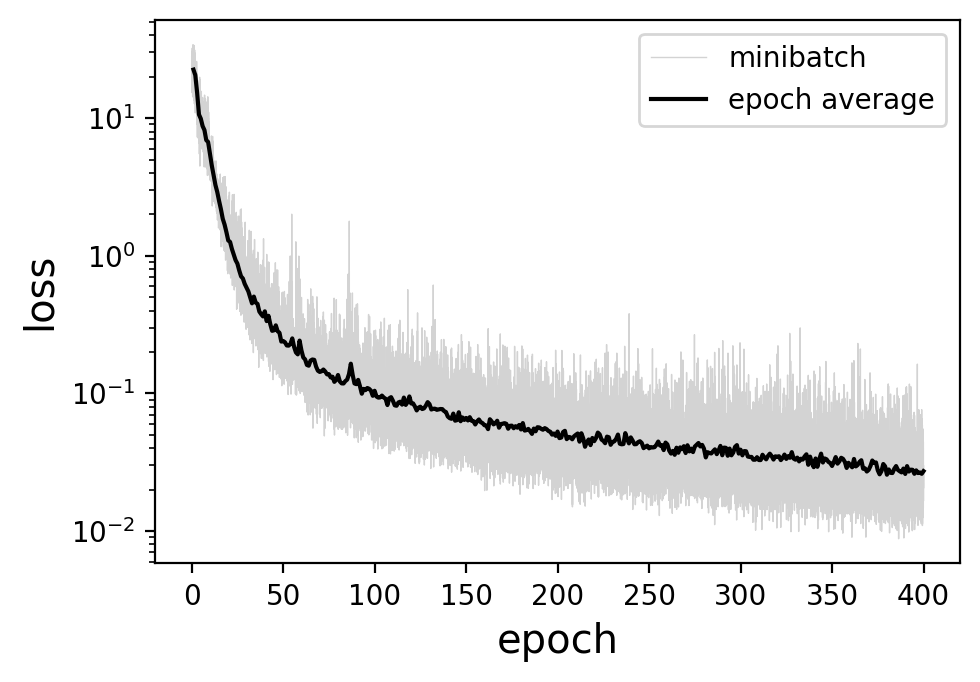

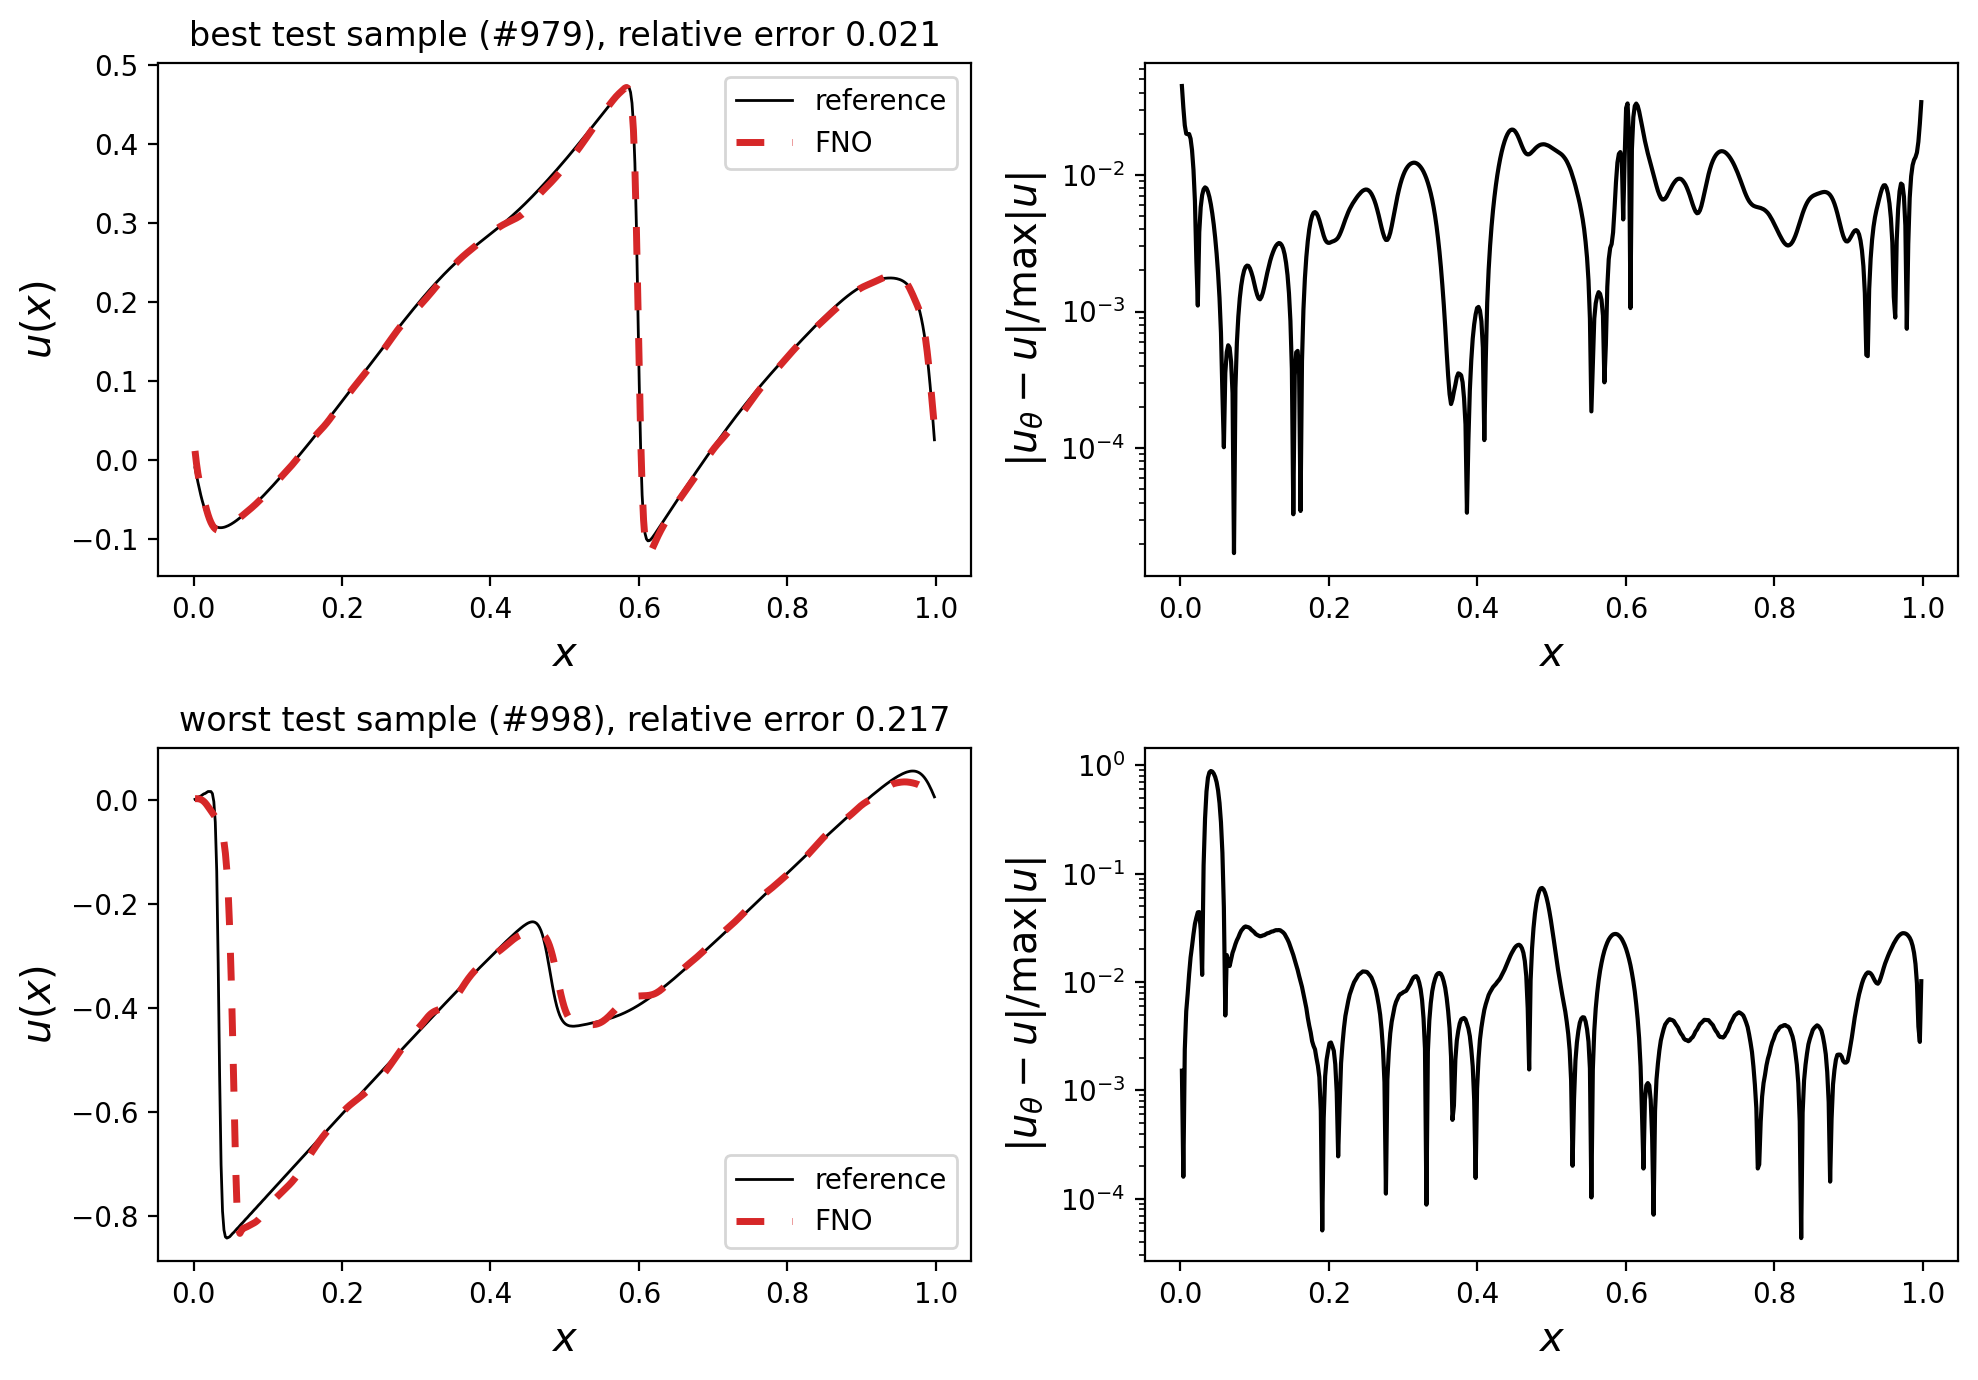

In [9]:
model, history, errors, predictions, targets, coordinates = train('Burgers')
plot_results(history, errors, predictions, targets, coordinates, figure_name='FNO_Burgers')

## Diffusion equation

Number of parameters: 557889
Training time: 33.8 s
Relative error      mean    median       min       max
  train           0.0757    0.0496    0.0100    0.9646
  test            0.1465    0.1015    0.0217    1.7162


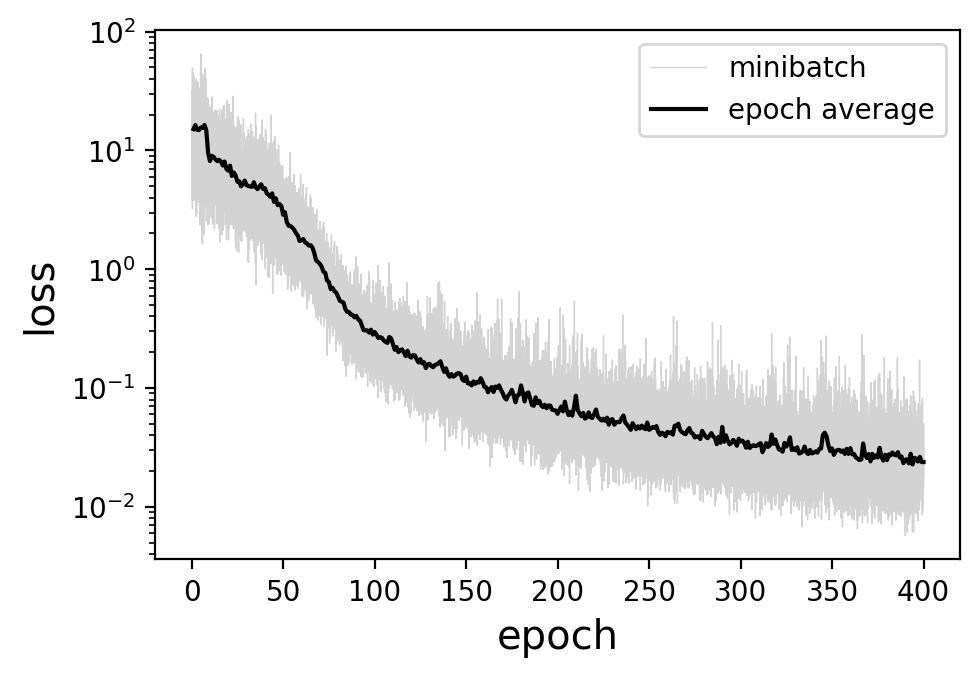

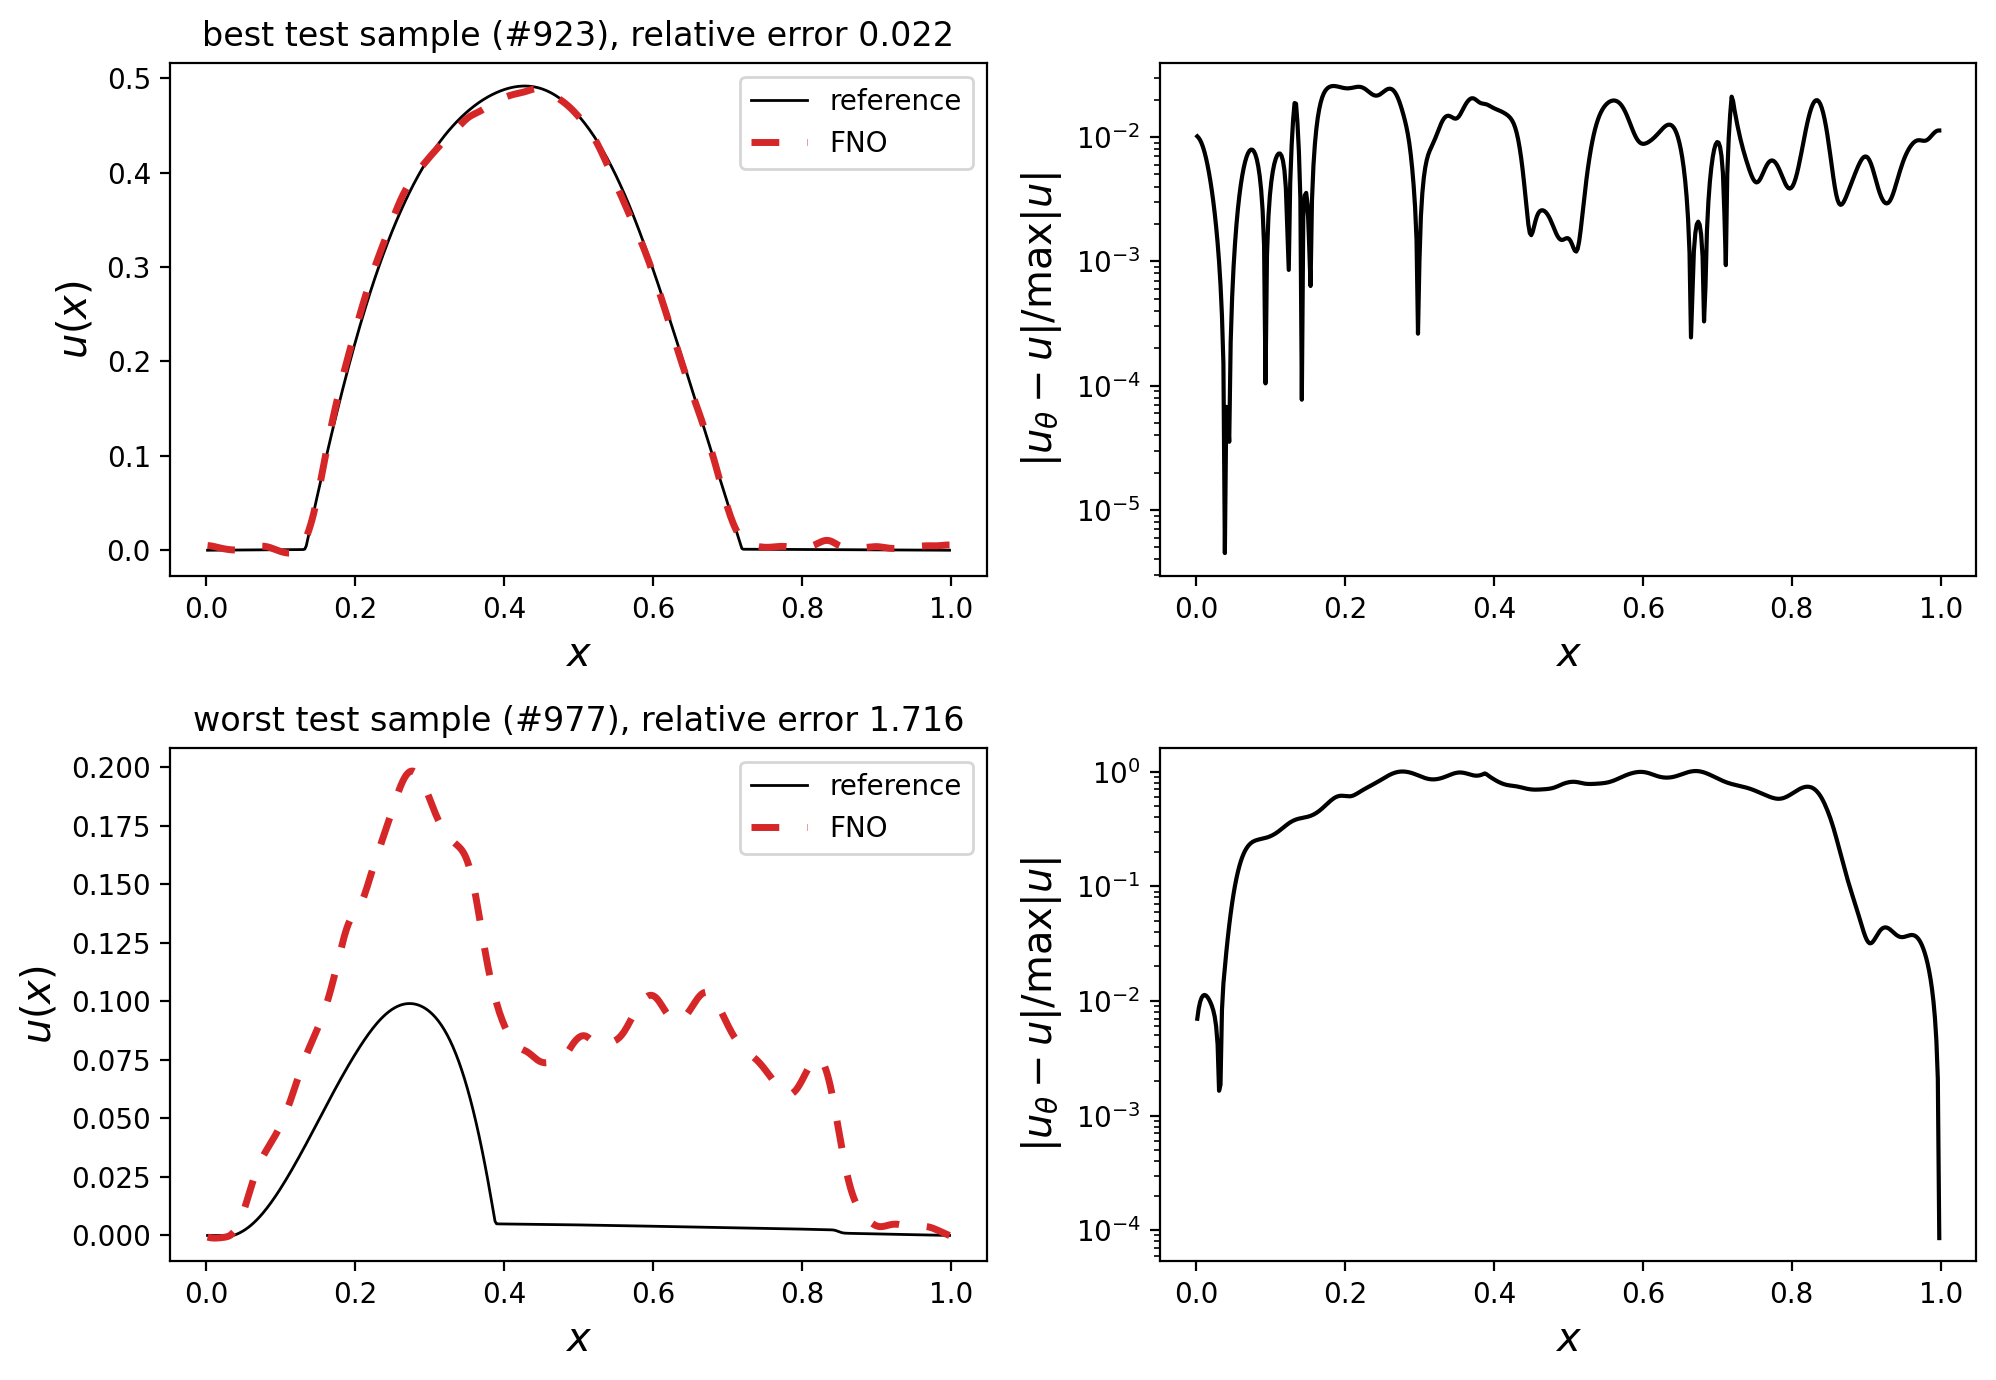

In [10]:
model, history, errors, predictions, targets, coordinates = train('Diffusion')
plot_results(history, errors, predictions, targets, coordinates, figure_name='FNO_Diffusion')

## Diffusion equation with a constant source term

The right-hand side is the same for all samples, so the only input channel is the coefficient $a(x)$.

Number of parameters: 557825
Training time: 33.5 s
Relative error      mean    median       min       max
  train           0.0263    0.0190    0.0050    0.1992
  test            0.0659    0.0498    0.0094    0.6156


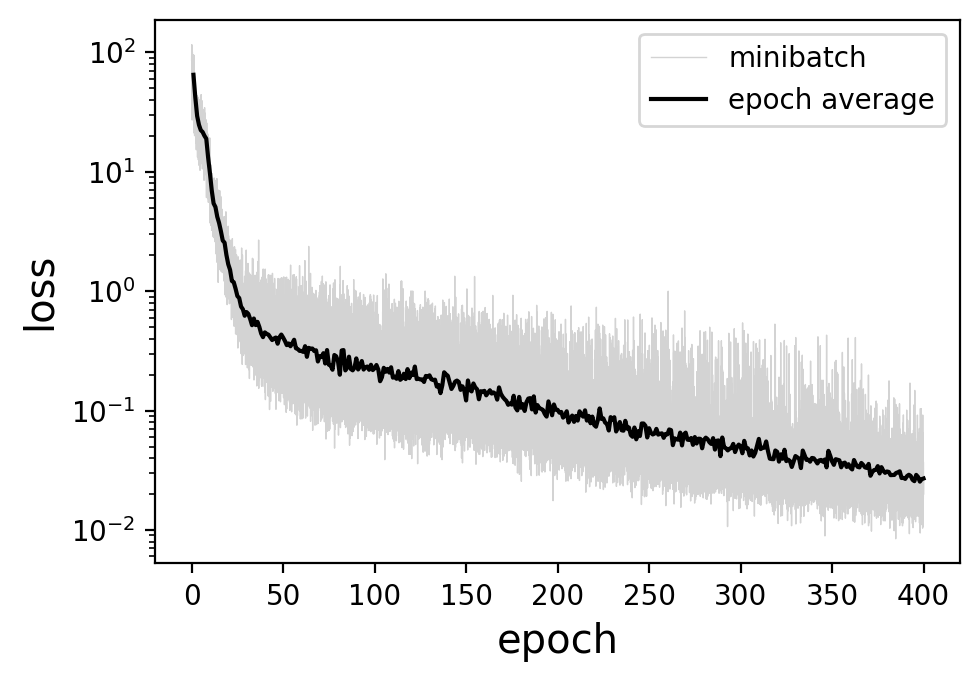

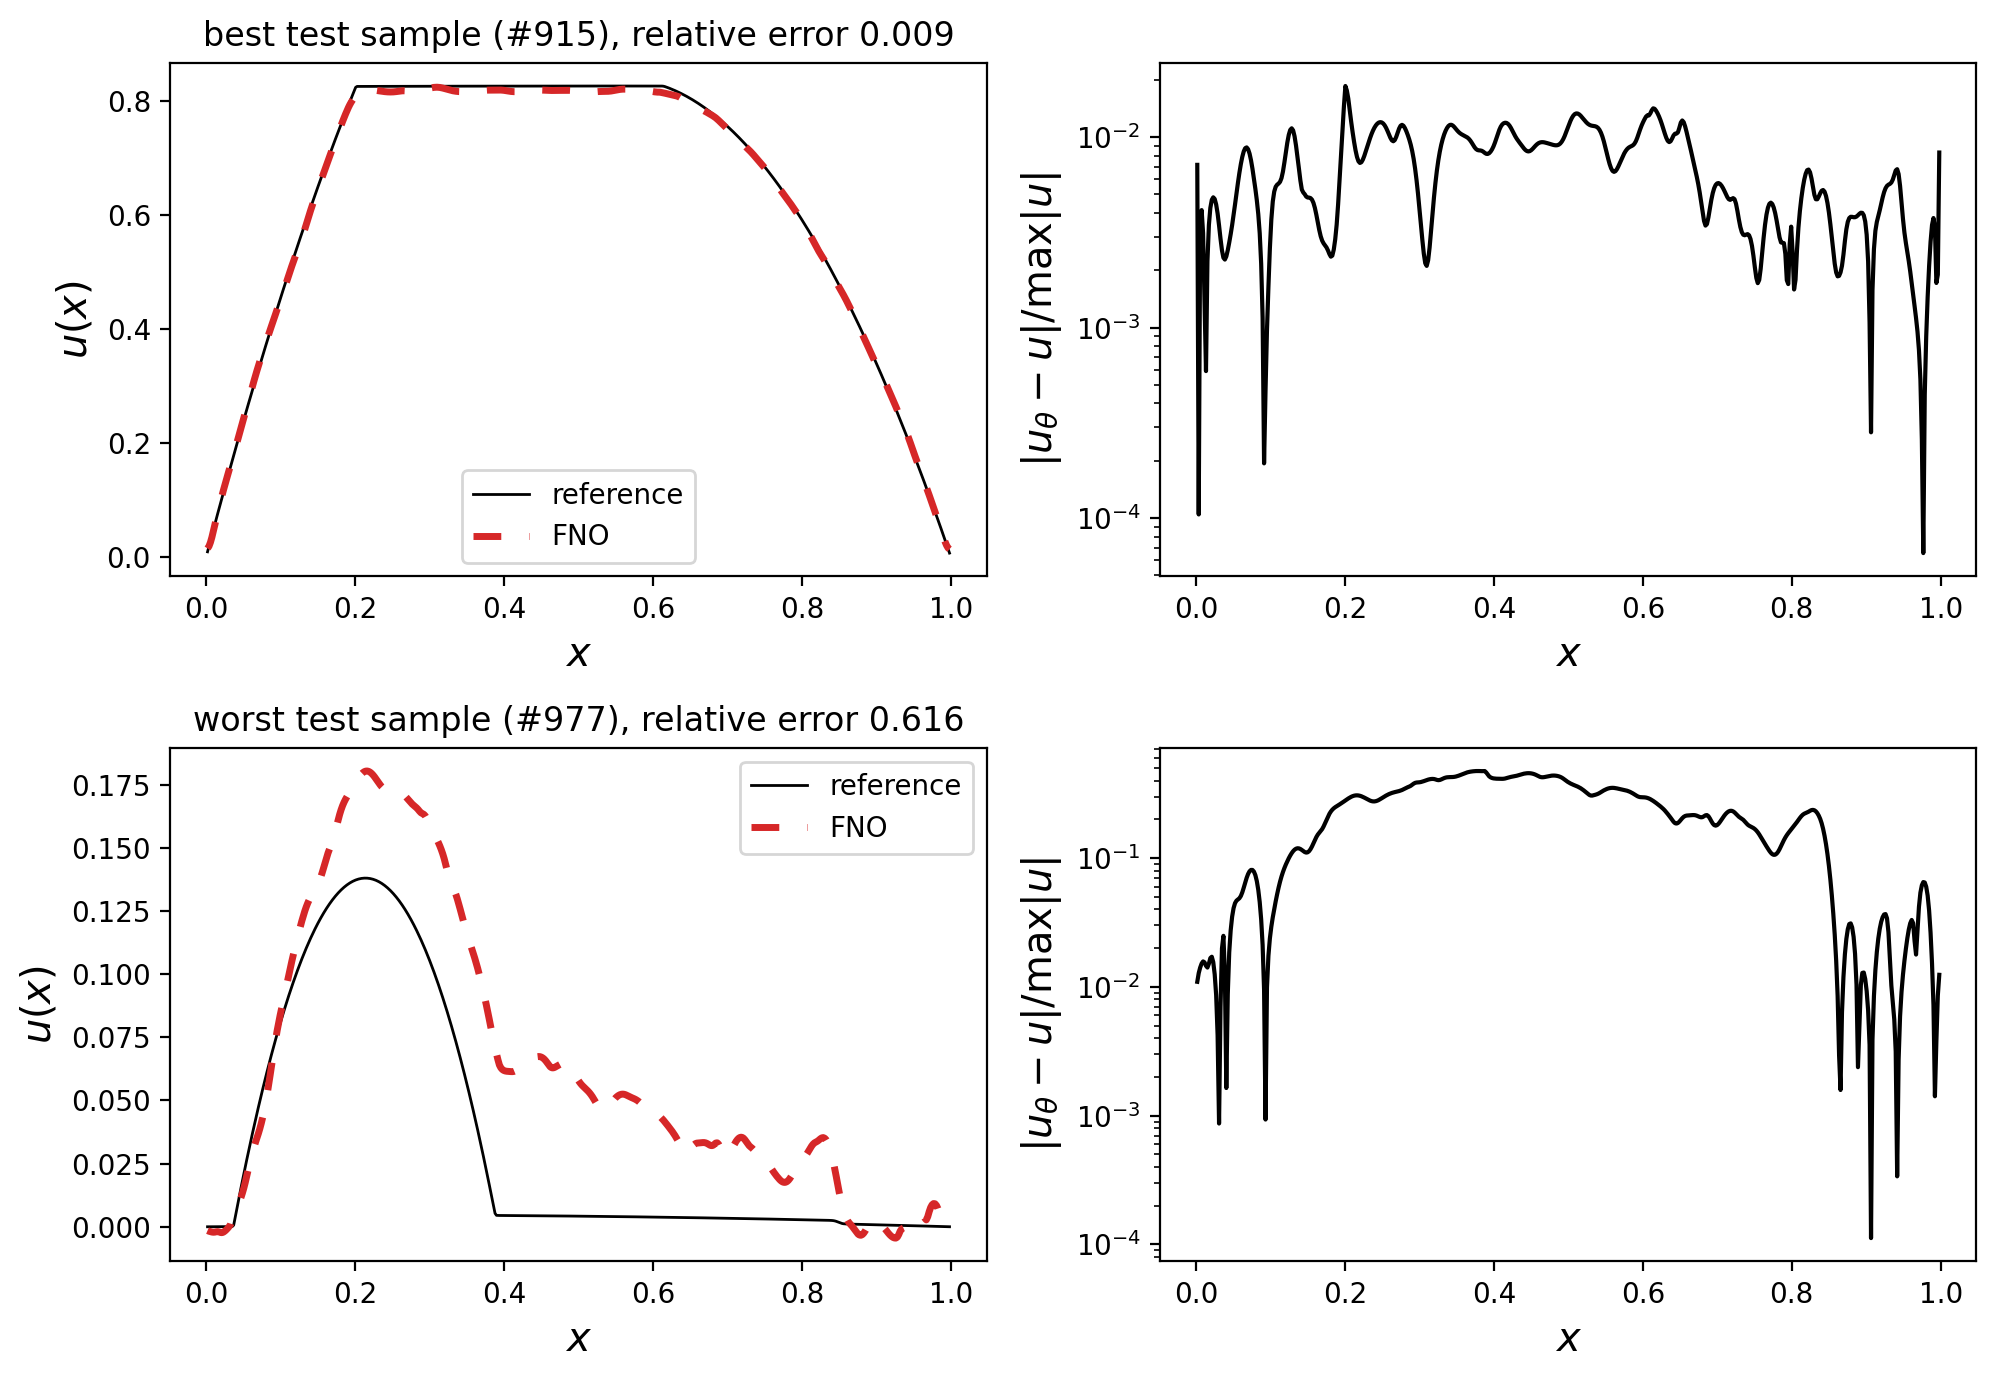

In [11]:
model, history, errors, predictions, targets, coordinates = train('Diffusion_constant_source')
plot_results(history, errors, predictions, targets, coordinates, figure_name='FNO_Diffusion_constant_source')

# Summary

Relative errors $\|u_\theta-u\|_2/\|u\|_2$ of the trained FNO (900 training and 100 test samples, 400 epochs, about 35 s of training for each problem):

| Dataset | Set | Mean | Median | Min | Max |
|---|---|---|---|---|---|
| Burgers | train | 0.0368 | 0.0325 | 0.0148 | 0.1278 |
| Burgers | test | 0.0528 | 0.0427 | 0.0214 | 0.2172 |
| Diffusion | train | 0.0757 | 0.0496 | 0.0100 | 0.9646 |
| Diffusion | test | 0.1465 | 0.1015 | 0.0217 | 1.7162 |
| Diffusion, constant source | train | 0.0263 | 0.0190 | 0.0050 | 0.1992 |
| Diffusion, constant source | test | 0.0659 | 0.0498 | 0.0094 | 0.6156 |

**Conclusion.** After a short training the FNO predicts the solution with a typical (median) test error of 4-10%, and a new problem is solved by a single forward pass. The quality depends on the problem: it is best for Burgers, where the maximal test error is 0.22, and worst for the diffusion equation with two input functions, where the worst test samples are not predicted at all (the error exceeds 1). In all cases the test error is larger than the training error, and the mean is larger than the median because of a few difficult samples, so the mean alone is not enough to judge the quality. The training was not tuned, and the results are only a baseline.